# Treino dos modelos com busca de hiperparâmetros

Mesma estrutura do `02-treino-modelos.ipynb`, mas agora cada modelo passa por uma **busca de hiperparâmetros** em vez de usar só a configuração inicial. Alvo `NU_NOTA_MT`, métrica principal RMSE (MAE, R² e MSE complementares), mesmas 3 dobras, teste reservado e fora de tudo isto.

**Otimizador: `RandomizedSearchCV`** (scikit-learn, o PDF aceita). Para cada modelo ele sorteia `N_ITER` configurações dentro de faixas que nós definimos, mede cada uma com a **validação cruzada nas mesmas 3 dobras**, escolhe a de menor RMSE médio e a reajusta nos 80% inteiros (`refit`). A semente 42 deixa o sorteio reproduzível.

| Seção | Modelo | Busca |
|---|---|---|
| 0 | Preparação | |
| 1 | Baseline e regressão linear | sem hiperparâmetros |
| 2 | Ridge | `alpha` |
| 3 | Árvore de decisão | profundidade, tamanho da folha, features por divisão |
| 4 | SVR linear | `C`, `epsilon` |
| 5 | Bagging | nº de árvores, amostra, features, árvore base |
| 6 | Pasting | idem |
| 7 | Random Forest | nº de árvores, profundidade, folha, features |
| 8 | Gradient Boosting | taxa de aprendizado, nº de árvores, folhas, regularização |
| 9 | Stacking | **sem busca** (custo) |
| 10 | KNN | **sem busca** (custo) |
| 11 | Comparação antes × depois da busca | |
| 12 | Comparação dos datasets com o modelo otimizado | |

**Atenção ao tempo:** cada configuração é treinada 3 vezes (uma por dobra) na base inteira. Com `N_ITER = 10` são 30 treinos por modelo. Estimativa total: **de 1h30 a 2h30**, a Random Forest sozinha pode levar quase 1 hora. Para encurtar, desligue modelos no dicionário `BUSCAR` da seção 0 ou diminua `N_ITER` (o PDF pede no mínimo 10 configurações nos 3 melhores modelos).

**Dois cuidados ao ler os resultados:**
- O RMSE da melhor configuração é um pouco **otimista**: ela foi escolhida justamente por ser a melhor entre `N_ITER` sorteadas. Diferenças menores que o desvio entre as dobras não provam melhora.
- O PDF pede a busca só nos **3 melhores regressores distintos**. Fazer a busca nos demais é exploratório.

## 0. Preparação

Igual ao notebook 02: lê o dataset, fica **só com o desenvolvimento** (80%), separa `X` e `y` e carrega as dobras salvas em `dados/splits/`. Depois vêm a função `avaliar` e as funções de gráficos (as mesmas do 02) e a função nova `buscar`, que faz a busca.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import PredefinedSplit, cross_val_predict, cross_validate

DATASETS = ["dataset_1_fundido", "dataset_1_features", "dataset_2_escola", "dataset_2_features_escola",
            "dataset_3_sem_escola", "dataset_3_sem_escola_features", "dataset_3_escola", "dataset_3_escola_features"]
NOME = "dataset_1_fundido"        # para treinar em outro dataset, troque só esta linha

# quem está no desenvolvimento (80%) e a dobra (1, 2 ou 3) de cada pessoa: arquivos salvos em dados/splits/
ids = pd.read_csv("../dados/processed/ids_elegiveis.csv")["NU_INSCRICAO"]
em_desenvolvimento = ids.isin(pd.read_csv("../dados/splits/desenvolvimento_ids.csv")["NU_INSCRICAO"]).to_numpy()
dobras = PredefinedSplit(pd.read_csv("../dados/splits/dobras_cv.csv")["dobra"].to_numpy())


def carregar(nome):
    """Lê o dataset e devolve só o desenvolvimento: X (features) e y (nota de Matemática). O teste não é carregado."""
    dev = pd.read_csv(f"../dados/processed/{nome}.csv")[em_desenvolvimento]
    return dev.drop(columns="NU_NOTA_MT"), dev["NU_NOTA_MT"]


X, y = carregar(NOME)
amostra = np.random.default_rng(42).choice(len(y), 20_000, replace=False)   # 20 mil pessoas sorteadas, só para desenhar gráficos
resultados = {}                                                             # métricas do melhor modelo de cada busca
print(f"{NOME}: {X.shape[0]:,} pessoas no desenvolvimento, {X.shape[1]} features")

dataset_1_fundido: 2,153,941 pessoas no desenvolvimento, 30 features


A função `avaliar` mede um modelo: ele treina em 2 dobras, é testado na terceira, três vezes, e ela devolve a **média** e o **desvio** de cada métrica. Se você passar um nome, o resultado também vai para `resultados`.

- **RMSE:** o erro típico em pontos de nota (pune mais os erros grandes). É a métrica principal.
- **MAE:** o erro médio em pontos, sem sinal.
- **R²:** quanto da variação da nota o modelo explica (0 = nada além da média, 1 = tudo).
- **MSE:** o erro ao quadrado médio; o RMSE é a raiz dele.
- **tempo_s:** segundos para treinar e prever em uma dobra.

In [2]:
def avaliar(modelo, nome=None):
    metricas = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error",
                "R2": "r2", "MSE": "neg_mean_squared_error"}      # o scikit-learn devolve os erros com sinal negativo
    r = cross_validate(modelo, X, y, cv=dobras, scoring=metricas)
    por_dobra = pd.DataFrame({"RMSE": -r["test_RMSE"], "MAE": -r["test_MAE"], "R2": r["test_R2"], "MSE": -r["test_MSE"],
                              "tempo_s": r["fit_time"] + r["score_time"]})
    resumo = pd.DataFrame({"média": por_dobra.mean(), "desvio": por_dobra.std()})
    if nome:
        resultados[nome] = resumo
    return resumo.round(3)

Três funções de apoio para os modelos que demoram. Elas treinam **na dobra 1** (não repetem a validação cruzada inteira):

- `real_x_previsto`: desenha 20 mil pessoas da validação, nota real contra nota prevista.
- `importancia_por_permutacao`: embaralha uma coluna da validação e mede **quanto o RMSE sobe**; quanto mais sobe, mais o modelo dependia daquela feature. Serve para qualquer modelo.
- `grafico_importancia`: desenha as 15 maiores.

In [3]:
from sklearn.inspection import permutation_importance


def treinar_dobra1(modelo):
    treino, validacao = next(iter(dobras.split()))
    return clone(modelo).fit(X.iloc[treino], y.iloc[treino]), validacao


def real_x_previsto(modelo, titulo):
    m, validacao = treinar_dobra1(modelo)
    sorteio = np.random.default_rng(42).choice(validacao, min(20_000, len(validacao)), replace=False)
    plt.figure(figsize=(6, 5))
    plt.scatter(y.iloc[sorteio], m.predict(X.iloc[sorteio]), s=3, alpha=0.1)
    plt.plot([0, 1000], [0, 1000], color="green", label="previsão perfeita")
    plt.title(f"Nota real x nota prevista ({titulo})")
    plt.xlabel("nota real")
    plt.ylabel("nota prevista")
    plt.legend()
    plt.show()


def importancia_por_permutacao(modelo, n_linhas=5000, repeticoes=3):
    m, validacao = treinar_dobra1(modelo)
    sorteio = np.random.default_rng(42).choice(validacao, min(n_linhas, len(validacao)), replace=False)
    r = permutation_importance(m, X.iloc[sorteio], y.iloc[sorteio], scoring="neg_root_mean_squared_error",
                               n_repeats=repeticoes, random_state=42)
    return pd.Series(r.importances_mean, index=X.columns).sort_values()


def grafico_importancia(serie, titulo, xlabel):
    top = serie.tail(15)
    plt.figure(figsize=(7, 5))
    plt.barh(top.index, top.values)
    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.show()

**A função `buscar`.** Recebe o modelo, as **faixas** de cada hiperparâmetro e o nome. As faixas podem ser:

- uma **lista** (`[0.5, 0.7, 1.0]`): o sorteio escolhe um dos valores;
- `randint(a, b)`: um número inteiro qualquer entre `a` e `b-1`;
- `uniform(a, largura)`: um número real entre `a` e `a + largura`;
- `loguniform(a, b)`: um real entre `a` e `b` sorteado em **escala logarítmica** (igual chance para 0,01, 0,1 e 1; usada quando o valor pode variar por ordens de grandeza, como `alpha` e `learning_rate`).

Cada configuração é medida com MSE, RMSE, MAE e R² nas 3 dobras; a escolha é pelo RMSE. A tabela completa da busca é gravada em `resultados/tabelas/busca_<modelo>.csv`, como o PDF pede (espaço de busca, critério e resultados).

In [4]:
import time
from pathlib import Path

from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

N_ITER = 10                       # configurações sorteadas por modelo (o PDF pede no mínimo 10)
BUSCAR = {"Ridge": True, "Árvore de decisão": True, "SVR linear": True, "Bagging": True,
          "Pasting": True, "Random Forest": True, "Gradient Boosting": True}      # False pula a busca daquele modelo
melhores = {}                     # melhor modelo de cada busca, já reajustado nos 80%
parametros = {}                   # os melhores hiperparâmetros de cada busca
Path("../resultados/tabelas").mkdir(parents=True, exist_ok=True)


def buscar(modelo, espaco, nome):
    metricas = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error",
                "R2": "r2", "MSE": "neg_mean_squared_error"}
    busca = RandomizedSearchCV(modelo, espaco, n_iter=N_ITER, cv=dobras, scoring=metricas, refit="RMSE",
                               random_state=42, n_jobs=1)
    t0 = time.time()
    busca.fit(X, y)                                                        # testa as N_ITER configurações e reajusta a melhor nos 80%
    minutos = (time.time() - t0) / 60

    r = pd.DataFrame(busca.cv_results_)
    melhor = busca.best_index_
    media, desvio = {}, {}
    for m, sinal in {"RMSE": -1, "MAE": -1, "R2": 1, "MSE": -1}.items():
        media[m], desvio[m] = sinal * r.loc[melhor, f"mean_test_{m}"], r.loc[melhor, f"std_test_{m}"]
    media["tempo_s"] = r.loc[melhor, "mean_fit_time"] + r.loc[melhor, "mean_score_time"]
    desvio["tempo_s"] = r.loc[melhor, "std_fit_time"]
    resultados[nome] = pd.DataFrame({"média": media, "desvio": desvio})
    melhores[nome], parametros[nome] = busca.best_estimator_, busca.best_params_

    tabela = pd.DataFrame({"parametros": [str(p) for p in r["params"]], "RMSE": -r["mean_test_RMSE"],
                           "RMSE_desvio": r["std_test_RMSE"], "MAE": -r["mean_test_MAE"], "R2": r["mean_test_R2"],
                           "tempo_s": r["mean_fit_time"] + r["mean_score_time"]}).sort_values("RMSE")
    tabela.to_csv(f"../resultados/tabelas/busca_{nome.lower().replace(' ', '_')}.csv", index=False)
    print(f"{nome}: {N_ITER} configurações em {minutos:.1f} min")
    print("Melhores hiperparâmetros:", busca.best_params_)
    print(f"RMSE nas 3 dobras: {media['RMSE']:.3f} ± {desvio['RMSE']:.3f}   (R² {media['R2']:.3f})")
    return tabela.head(5).round(3)

## 1. Baseline pela média

**O que é:** `DummyRegressor(strategy="mean")`: aprende a média da nota no treino e prevê esse mesmo valor para todos, sem usar nenhuma feature.

**Pontos de atenção:** É a referência do erro: qualquer modelo útil precisa ficar abaixo do RMSE dele. A média é recalculada no treino de cada dobra (e, no teste final, nos 80% de desenvolvimento), nunca com o teste. Não tem hiperparâmetros.

Baseline e regressão linear **não têm hiperparâmetros**, então não há o que buscar. Os resultados deles estão no `02-treino-modelos.ipynb` e entram na comparação da seção 11 (se você salvar a tabela de lá, veja a seção 11).

## 2. Regressão linear (sem e com regularização)

**O que é:** `LinearRegression` (sem regularização) e `Ridge` ou `Lasso` (com regularização): a nota é uma soma ponderada das features. A regularização encolhe os pesos para a conta não ficar instável quando as colunas se parecem.

**Pontos de atenção:** O PDF pede as duas versões. Precisa de `StandardScaler` dentro do Pipeline. A regressão sem regularização também é reajustada nos 80% e avaliada no teste final. Hiperparâmetro: `alpha`.

### Passo 1: a busca

O `alpha` é a força do freio do Ridge. Sorteamos de 0,001 a 100.000 em escala logarítmica. No seu README já se viu que de 0,001 a 100 o resultado quase não muda e só piora quando o freio fica muito forte, então espere um resultado parecido com o do `alpha=1`.

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

if BUSCAR["Ridge"]:
    ridge = make_pipeline(StandardScaler(), Ridge())
    espaco = {"ridge__alpha": loguniform(1e-3, 1e5)}
    top = buscar(ridge, espaco, "Ridge")
top

Ridge: 10 configurações em 0.6 min
Melhores hiperparâmetros: {'ridge__alpha': np.float64(461.93473743773814)}
RMSE nas 3 dobras: 111.153 ± 0.145   (R² 0.287)


,parametros,RMSE,RMSE_desvio,MAE,R2,tempo_s
9,{'ridge__alpha': np.float64(461.93473743773814)},111.153,0.145,86.961,0.287,0.952
8,{'ridge__alpha': np.float64(64.40507553993716)},111.153,0.145,86.960,0.287,1.008
3,{'ridge__alpha': np.float64(61.55564318973023)},111.153,0.145,86.960,0.287,0.829
0,{'ridge__alpha': np.float64(0.9915644566638395)},111.153,0.145,86.960,0.287,1.715
4,{'ridge__alpha': np.float64(0.0177071686435378...,111.153,0.145,86.960,0.287,0.870


### Passo 2: as features que mais influenciaram

Pesos do Ridge (pontos de nota por desvio padrão da feature).

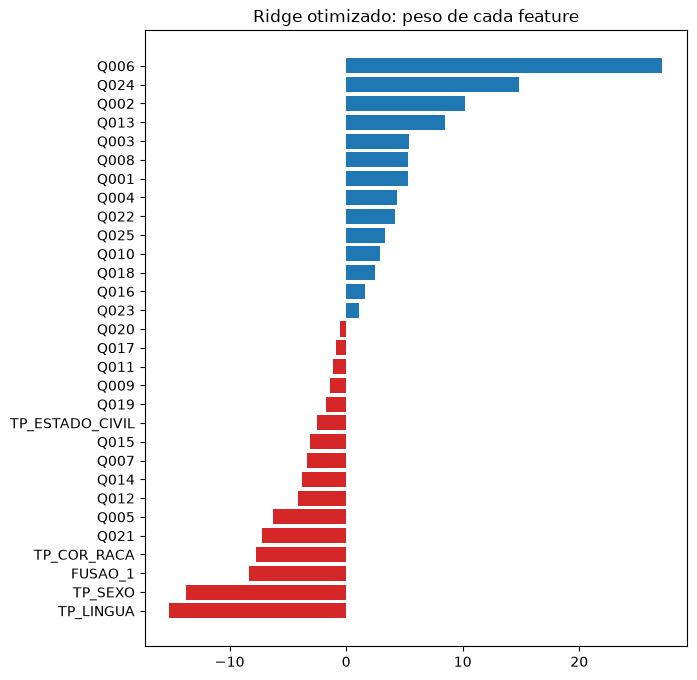

In [6]:
if "Ridge" in melhores:
    pesos = pd.Series(melhores["Ridge"][-1].coef_, index=X.columns).sort_values()
    plt.figure(figsize=(7, 8))
    plt.barh(pesos.index, pesos.values, color=["tab:red" if v < 0 else "tab:blue" for v in pesos.values])
    plt.title("Ridge otimizado: peso de cada feature")
    plt.show()

### Passo 3: nota real × nota prevista e salvar

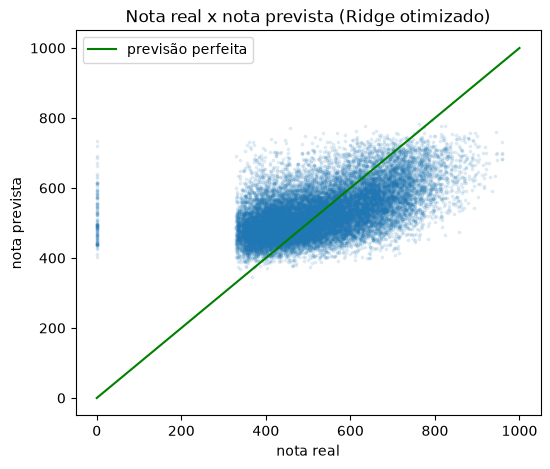

In [7]:
if "Ridge" in melhores:
    real_x_previsto(melhores["Ridge"], "Ridge otimizado")
    joblib.dump(melhores["Ridge"], f"../models/ridge_otimizado_{NOME}.joblib")

## 3. Árvore de decisão

**O que é:** `DecisionTreeRegressor`: divide os participantes em grupos por perguntas do tipo "`Q006` > 5?" e prevê a média da nota de cada grupo.

**Pontos de atenção:** Não precisa padronizar e aproveita relações que não são em linha reta. Sozinha tende a decorar o treino, então a profundidade precisa ser limitada. Hiperparâmetros: `max_depth`, `min_samples_leaf`, `min_samples_split`.

### Passo 1: a busca

Faixas: `max_depth` de 5 a 30 (a seção 3 do notebook 02 mostrou que passar de ~10 já começa a decorar o treino), `min_samples_leaf` de 5 a 299 e `max_features` (fração das features que a árvore olha em cada divisão; `None` = todas). Estimativa: cerca de 5 minutos.

In [8]:
from sklearn.tree import DecisionTreeRegressor

if BUSCAR["Árvore de decisão"]:
    arvore = DecisionTreeRegressor(random_state=42)
    espaco = {"max_depth": randint(5, 31), "min_samples_leaf": randint(5, 300), "max_features": [None, 0.8, 0.5]}
    top = buscar(arvore, espaco, "Árvore de decisão")
top

Árvore de decisão: 10 configurações em 4.7 min
Melhores hiperparâmetros: {'max_depth': 25, 'max_features': 0.8, 'min_samples_leaf': 298}
RMSE nas 3 dobras: 110.337 ± 0.148   (R² 0.297)


,parametros,RMSE,RMSE_desvio,MAE,R2,tempo_s
5,"{'max_depth': 25, 'max_features': 0.8, 'min_sa...",110.337,0.148,86.113,0.297,8.310
0,"{'max_depth': 11, 'max_features': None, 'min_s...",110.388,0.153,86.219,0.297,7.983
9,"{'max_depth': 14, 'max_features': 0.5, 'min_sa...",110.400,0.146,86.192,0.297,10.262
4,"{'max_depth': 25, 'max_features': 0.5, 'min_sa...",110.457,0.140,86.192,0.296,5.098
3,"{'max_depth': 15, 'max_features': 0.5, 'min_sa...",110.499,0.152,86.193,0.295,6.235


### Passo 2: as features que mais influenciaram

`feature_importances_` da melhor árvore (soma 1).

Q003         0.036
TP_SEXO      0.036
FUSAO_1      0.049
TP_LINGUA    0.081
Q006         0.256
Q024         0.424


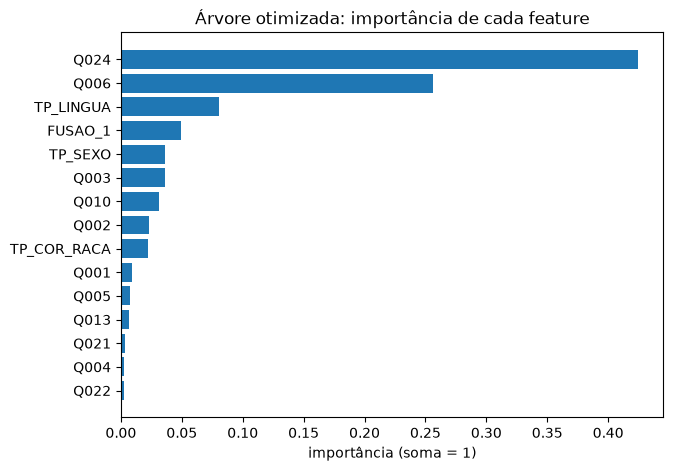

In [9]:
if "Árvore de decisão" in melhores:
    imp = pd.Series(melhores["Árvore de decisão"].feature_importances_, index=X.columns).sort_values()
    print(imp.tail(6).round(3).to_string())
    grafico_importancia(imp, "Árvore otimizada: importância de cada feature", "importância (soma = 1)")

### Passo 3: nota real × nota prevista e salvar

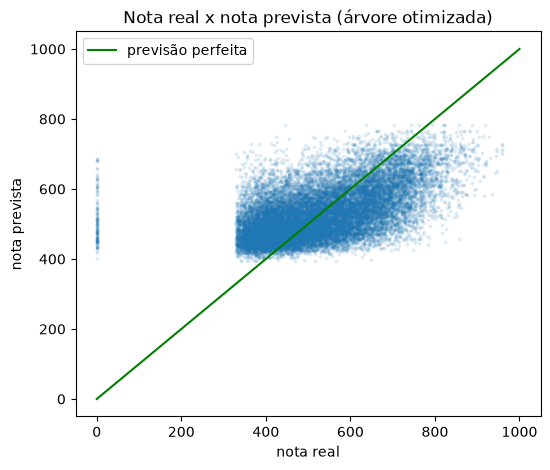

In [10]:
if "Árvore de decisão" in melhores:
    real_x_previsto(melhores["Árvore de decisão"], "árvore otimizada")
    joblib.dump(melhores["Árvore de decisão"], f"../models/arvore_decisao_otimizada_{NOME}.joblib")

## 4. SVR (máquina de vetores de suporte)

**O que é:** `SVR`: ajusta uma curva que tenta errar no máximo `epsilon` para a maioria dos pontos e só penaliza quem passa disso. O kernel (linear, RBF, polinomial) define o formato da curva.

**Pontos de atenção:** O PDF pede justificar o kernel; `LinearSVR` também é permitido. O SVR com kernel é muito pesado com milhões de linhas, então vale registrar o tempo e, se preciso, usar o `LinearSVR`. Precisa de `StandardScaler`. Hiperparâmetros: `kernel`, `C`, `epsilon`, `gamma`.

### Passo 1: a busca

Só o `LinearSVR` cabe com 2 milhões de linhas (o kernel RBF custa o quadrado do tamanho da base, veja a seção 4 do 02). Hiperparâmetros: `C` (quão duramente pune o erro; de 0,01 a 10, escala log) e `epsilon` (margem sem punição; de 0 a 5 pontos). Estimativa: de 10 a 30 minutos, é o tempo que eu menos conheço.

In [11]:
from sklearn.svm import LinearSVR

if BUSCAR["SVR linear"]:
    svr = make_pipeline(StandardScaler(), LinearSVR(loss="squared_epsilon_insensitive", dual=False, max_iter=5000, random_state=42))
    espaco = {"linearsvr__C": loguniform(1e-2, 1e1), "linearsvr__epsilon": uniform(0, 5)}
    top = buscar(svr, espaco, "SVR linear")
top

SVR linear: 10 configurações em 2.0 min
Melhores hiperparâmetros: {'linearsvr__C': np.float64(0.02938027938703535), 'linearsvr__epsilon': np.float64(0.7799726016810132)}
RMSE nas 3 dobras: 111.153 ± 0.145   (R² 0.287)


,parametros,RMSE,RMSE_desvio,MAE,R2,tempo_s
2,{'linearsvr__C': np.float64(0.0293802793870353...,111.153,0.145,86.966,0.287,5.846
7,{'linearsvr__C': np.float64(0.0351135631397040...,111.153,0.145,86.966,0.287,2.599
6,{'linearsvr__C': np.float64(3.142880890840109)...,111.153,0.145,86.967,0.287,0.963
9,{'linearsvr__C': np.float64(0.1976218934028007...,111.153,0.145,86.969,0.287,4.231
8,{'linearsvr__C': np.float64(0.0817949947521167...,111.153,0.145,86.976,0.287,2.948


### Passo 2: as features que mais influenciaram

Pesos (`coef_`), como no kernel linear.

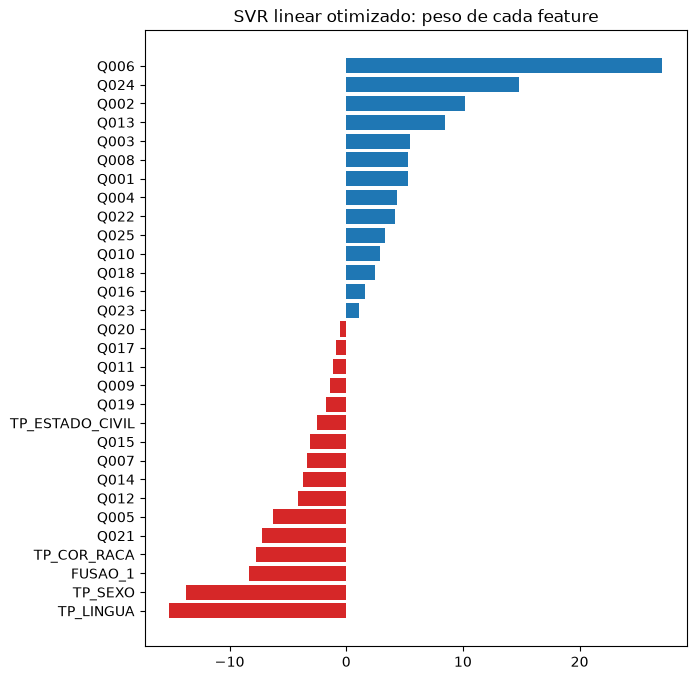

In [12]:
if "SVR linear" in melhores:
    pesos = pd.Series(melhores["SVR linear"][-1].coef_, index=X.columns).sort_values()
    plt.figure(figsize=(7, 8))
    plt.barh(pesos.index, pesos.values, color=["tab:red" if v < 0 else "tab:blue" for v in pesos.values])
    plt.title("SVR linear otimizado: peso de cada feature")
    plt.show()

### Passo 3: nota real × nota prevista e salvar

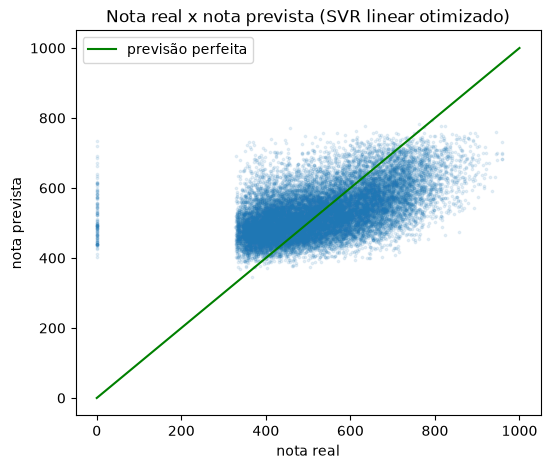

In [13]:
if "SVR linear" in melhores:
    real_x_previsto(melhores["SVR linear"], "SVR linear otimizado")
    joblib.dump(melhores["SVR linear"], f"../models/svr_linear_otimizado_{NOME}.joblib")

## 5. Bagging

**O que é:** `BaggingRegressor(bootstrap=True)`: treina vários modelos iguais, cada um numa amostra sorteada **com reposição**, e prevê a média deles.

**Pontos de atenção:** Reduz a variância de modelos instáveis, como a árvore. As subamostras são um mecanismo do algoritmo e não substituem a base nacional por um recorte. Hiperparâmetros: `n_estimators`, `max_samples`, `max_features`, modelo base.

### Passo 1: a busca

Faixas: `n_estimators` (nº de árvores, de 10 a 40), `max_samples`, `max_features` (fração das features de cada árvore) e os da árvore base (`max_depth` de 6 a 15, `min_samples_leaf` de 20 a 199). `max_samples` é a fração do treino de cada árvore (com reposição). Estimativa: de 8 a 15 minutos.

In [14]:
from sklearn.ensemble import BaggingRegressor

if BUSCAR["Bagging"]:
    bagging = BaggingRegressor(estimator=DecisionTreeRegressor(), bootstrap=True, n_jobs=-1, random_state=42)
    espaco = {"n_estimators": randint(10, 41), "max_samples": [0.5, 0.7, 1.0], "max_features": [0.6, 0.8, 1.0],
              "estimator__max_depth": randint(6, 16), "estimator__min_samples_leaf": randint(20, 200)}
    top = buscar(bagging, espaco, "Bagging")
top

Bagging: 10 configurações em 17.8 min
Melhores hiperparâmetros: {'estimator__max_depth': 15, 'estimator__min_samples_leaf': 34, 'max_features': 0.8, 'max_samples': 0.7, 'n_estimators': 24}
RMSE nas 3 dobras: 109.083 ± 0.154   (R² 0.313)


,parametros,RMSE,RMSE_desvio,MAE,R2,tempo_s
7,"{'estimator__max_depth': 15, 'estimator__min_s...",109.083,0.154,85.273,0.313,23.760
6,"{'estimator__max_depth': 14, 'estimator__min_s...",109.338,0.157,85.326,0.310,51.714
1,"{'estimator__max_depth': 13, 'estimator__min_s...",109.365,0.157,85.368,0.310,55.168
3,"{'estimator__max_depth': 13, 'estimator__min_s...",109.585,0.163,85.579,0.307,55.213
2,"{'estimator__max_depth': 12, 'estimator__min_s...",109.611,0.157,85.603,0.307,24.640


### Passo 2: as features que mais influenciaram

Importância por permutação (quanto o RMSE sobe ao embaralhar a feature), na validação da dobra 1.

TP_COR_RACA    0.74
TP_SEXO        1.59
Q024           1.63
TP_LINGUA      2.50
FUSAO_1        2.80
Q006           5.92


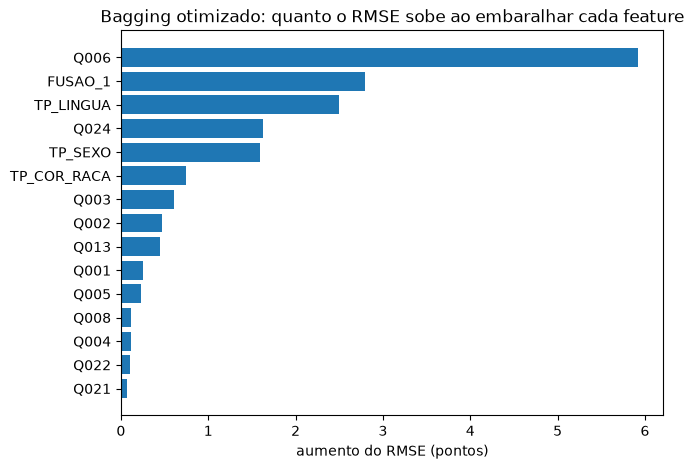

In [15]:
if "Bagging" in melhores:
    imp = importancia_por_permutacao(melhores["Bagging"])
    print(imp.tail(6).round(2).to_string())
    grafico_importancia(imp, "Bagging otimizado: quanto o RMSE sobe ao embaralhar cada feature", "aumento do RMSE (pontos)")

### Passo 3: nota real × nota prevista e salvar

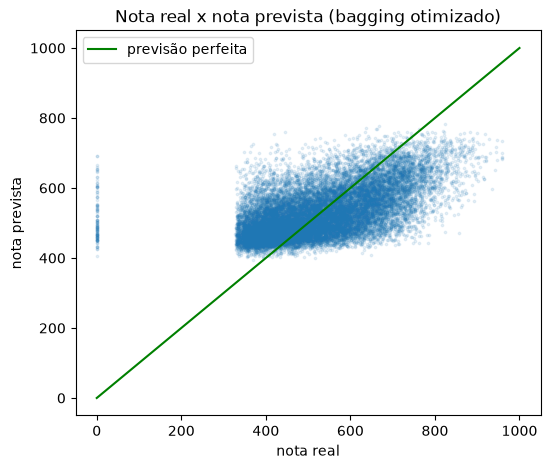

In [16]:
if "Bagging" in melhores:
    real_x_previsto(melhores["Bagging"], "bagging otimizado")
    joblib.dump(melhores["Bagging"], f"../models/bagging_otimizado_{NOME}.joblib")

## 6. Pasting

**O que é:** `BaggingRegressor(bootstrap=False)` com `max_samples` menor que 1: igual ao bagging, mas cada subamostra é sorteada **sem reposição**.

**Pontos de atenção:** É a segunda forma de combinar modelos que o PDF pede; comparar com o bagging mostra o efeito da reposição. Hiperparâmetros: `n_estimators`, `max_samples`, `max_features`, modelo base.

### Passo 1: a busca

Faixas: `n_estimators` (nº de árvores, de 10 a 40), `max_samples`, `max_features` (fração das features de cada árvore) e os da árvore base (`max_depth` de 6 a 15, `min_samples_leaf` de 20 a 199). `max_samples` é a fração do treino de cada árvore (sem reposição; precisa ser menor que 1). Estimativa: de 8 a 15 minutos.

In [17]:
from sklearn.ensemble import BaggingRegressor

if BUSCAR["Pasting"]:
    pasting = BaggingRegressor(estimator=DecisionTreeRegressor(), bootstrap=False, n_jobs=-1, random_state=42)
    espaco = {"n_estimators": randint(10, 41), "max_samples": [0.2, 0.3, 0.5, 0.7], "max_features": [0.6, 0.8, 1.0],
              "estimator__max_depth": randint(6, 16), "estimator__min_samples_leaf": randint(20, 200)}
    top = buscar(pasting, espaco, "Pasting")
top

Pasting: 10 configurações em 12.0 min
Melhores hiperparâmetros: {'estimator__max_depth': 15, 'estimator__min_samples_leaf': 34, 'max_features': 0.8, 'max_samples': 0.3, 'n_estimators': 24}
RMSE nas 3 dobras: 109.146 ± 0.158   (R² 0.312)


,parametros,RMSE,RMSE_desvio,MAE,R2,tempo_s
7,"{'estimator__max_depth': 15, 'estimator__min_s...",109.146,0.158,85.340,0.312,18.098
1,"{'estimator__max_depth': 13, 'estimator__min_s...",109.353,0.157,85.370,0.310,20.137
6,"{'estimator__max_depth': 14, 'estimator__min_s...",109.372,0.158,85.362,0.310,40.900
2,"{'estimator__max_depth': 12, 'estimator__min_s...",109.690,0.164,85.654,0.306,44.973
5,"{'estimator__max_depth': 10, 'estimator__min_s...",109.847,0.169,86.039,0.304,24.752


### Passo 2: as features que mais influenciaram

Importância por permutação (quanto o RMSE sobe ao embaralhar a feature), na validação da dobra 1.

TP_COR_RACA    0.84
Q024           1.57
TP_SEXO        1.60
TP_LINGUA      2.54
FUSAO_1        2.77
Q006           6.10


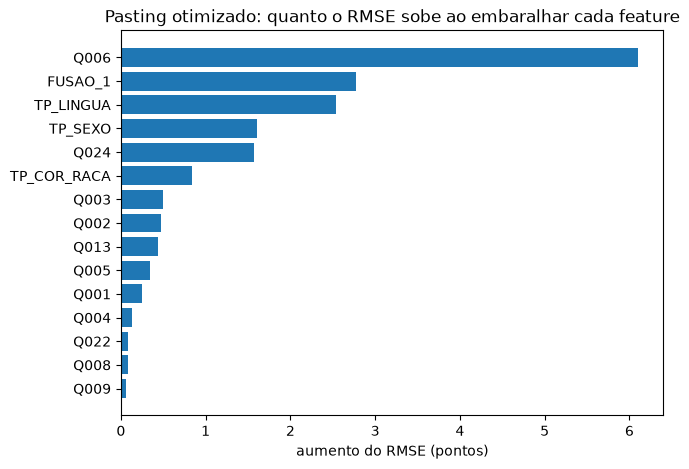

In [18]:
if "Pasting" in melhores:
    imp = importancia_por_permutacao(melhores["Pasting"])
    print(imp.tail(6).round(2).to_string())
    grafico_importancia(imp, "Pasting otimizado: quanto o RMSE sobe ao embaralhar cada feature", "aumento do RMSE (pontos)")

### Passo 3: nota real × nota prevista e salvar

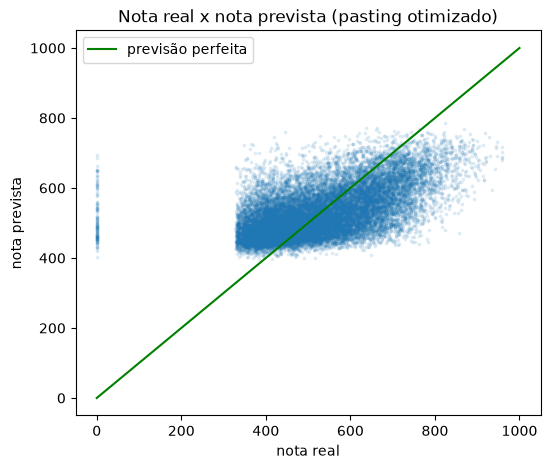

In [19]:
if "Pasting" in melhores:
    real_x_previsto(melhores["Pasting"], "pasting otimizado")
    joblib.dump(melhores["Pasting"], f"../models/pasting_otimizado_{NOME}.joblib")

## 7. Random Forest

**O que é:** `RandomForestRegressor`: várias árvores, cada uma numa amostra e escolhendo entre um sorteio de colunas a cada divisão; a previsão é a média das árvores.

**Pontos de atenção:** É um bagging de árvores com sorteio de colunas, em geral bem mais forte que uma árvore só. Com 2 milhões de linhas, limitar `n_estimators` e `max_depth`. Hiperparâmetros: `n_estimators`, `max_depth`, `max_features`, `min_samples_leaf`.

### Passo 1: a busca

Faixas: `n_estimators` 50 ou 100, `max_depth` de 8 a 15, `min_samples_leaf` de 10 a 199, `max_features` 0,3, 0,5 ou 0,7. Mantive as faixas moderadas porque é o modelo mais caro da busca. **Estimativa: de 40 a 60 minutos.**

In [20]:
from sklearn.ensemble import RandomForestRegressor

if BUSCAR["Random Forest"]:
    floresta = RandomForestRegressor(n_jobs=-1, random_state=42)
    espaco = {"n_estimators": [50, 100], "max_depth": randint(8, 16), "min_samples_leaf": randint(10, 200), "max_features": [0.3, 0.5, 0.7]}
    top = buscar(floresta, espaco, "Random Forest")
top

Random Forest: 10 configurações em 19.7 min
Melhores hiperparâmetros: {'max_depth': 15, 'max_features': 0.3, 'min_samples_leaf': 30, 'n_estimators': 50}
RMSE nas 3 dobras: 109.138 ± 0.159   (R² 0.313)


,parametros,RMSE,RMSE_desvio,MAE,R2,tempo_s
1,"{'max_depth': 15, 'max_features': 0.3, 'min_sa...",109.138,0.159,85.244,0.313,19.205
0,"{'max_depth': 14, 'max_features': 0.3, 'min_sa...",109.200,0.155,85.315,0.312,20.707
3,"{'max_depth': 15, 'max_features': 0.3, 'min_sa...",109.322,0.159,85.446,0.310,38.499
4,"{'max_depth': 15, 'max_features': 0.7, 'min_sa...",109.412,0.159,85.428,0.309,36.986
6,"{'max_depth': 15, 'max_features': 0.3, 'min_sa...",109.441,0.158,85.571,0.309,38.592


### Passo 2: as features que mais influenciaram

`feature_importances_` da floresta (média das árvores, soma 1).

FUSAO_1      0.053
Q001         0.062
TP_LINGUA    0.071
Q003         0.102
Q024         0.164
Q006         0.273


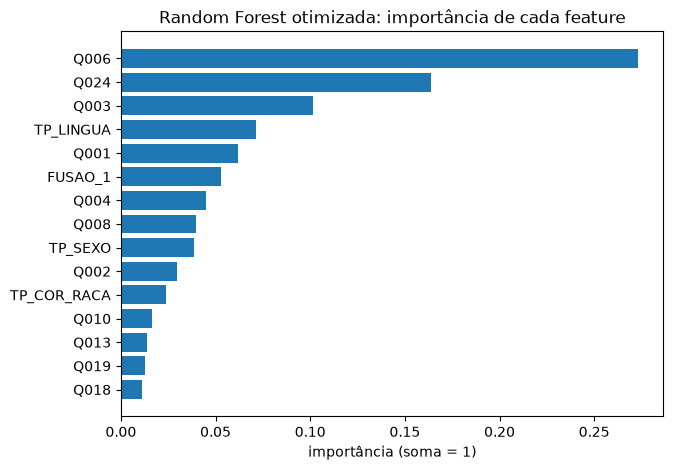

In [21]:
if "Random Forest" in melhores:
    imp = pd.Series(melhores["Random Forest"].feature_importances_, index=X.columns).sort_values()
    print(imp.tail(6).round(3).to_string())
    grafico_importancia(imp, "Random Forest otimizada: importância de cada feature", "importância (soma = 1)")

### Passo 3: nota real × nota prevista e salvar

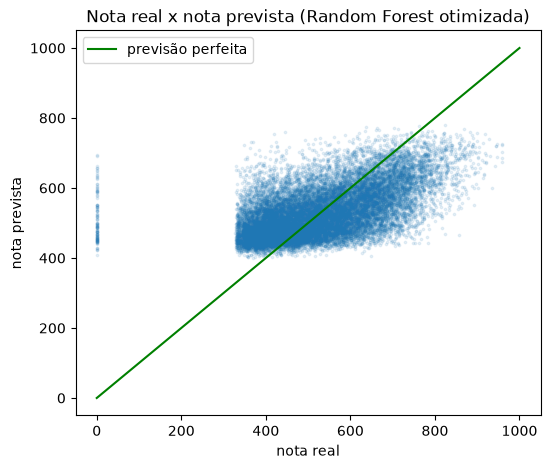

In [22]:
if "Random Forest" in melhores:
    real_x_previsto(melhores["Random Forest"], "Random Forest otimizada")
    joblib.dump(melhores["Random Forest"], f"../models/random_forest_otimizada_{NOME}.joblib")

## 8. Gradient Boosting

**O que é:** `GradientBoostingRegressor` ou `HistGradientBoostingRegressor`: árvores pequenas treinadas em sequência, cada uma corrigindo o erro das anteriores.

**Pontos de atenção:** O `HistGradientBoostingRegressor` é bem mais rápido em bases grandes. Se houver parada antecipada, usar uma parcela interna do treino da dobra, nunca o teste. Hiperparâmetros: `learning_rate`, `max_iter`, `max_depth`, `min_samples_leaf`.

### Passo 1: a busca

Faixas: `learning_rate` de 0,02 a 0,3 (escala log; quanto cada árvore corrige), `max_iter` 200, 300 ou 500 (nº máximo de árvores; a parada antecipada com 10% do treino da dobra pode parar antes), `max_leaf_nodes` de 15 a 99, `min_samples_leaf` de 50 a 499 e `l2_regularization` de 0,001 a 10 (escala log; freio nos pesos das folhas). Estimativa: de 15 a 25 minutos.

In [23]:
from sklearn.ensemble import HistGradientBoostingRegressor

if BUSCAR["Gradient Boosting"]:
    gradient_boosting = HistGradientBoostingRegressor(early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, random_state=42)
    espaco = {"learning_rate": loguniform(0.02, 0.3), "max_iter": [200, 300, 500], "max_leaf_nodes": randint(15, 100),
              "min_samples_leaf": randint(50, 500), "l2_regularization": loguniform(1e-3, 10)}
    top = buscar(gradient_boosting, espaco, "Gradient Boosting")
top

Gradient Boosting: 10 configurações em 54.2 min
Melhores hiperparâmetros: {'l2_regularization': np.float64(0.24400607090817547), 'learning_rate': np.float64(0.06689135590392836), 'max_iter': 500, 'max_leaf_nodes': 89, 'min_samples_leaf': 137}
RMSE nas 3 dobras: 107.680 ± 0.178   (R² 0.331)


,parametros,RMSE,RMSE_desvio,MAE,R2,tempo_s
1,{'l2_regularization': np.float64(0.24400607090...,107.680,0.178,83.714,0.331,223.988
6,{'l2_regularization': np.float64(0.02920433847...,107.688,0.179,83.728,0.331,167.684
5,{'l2_regularization': np.float64(0.05342937261...,107.719,0.173,83.773,0.330,185.941
9,{'l2_regularization': np.float64(7.28665373749...,107.721,0.169,83.736,0.330,56.461
4,{'l2_regularization': np.float64(9.30778273202...,107.734,0.179,83.780,0.330,81.484


### Passo 2: as features que mais influenciaram

O `HistGradientBoostingRegressor` não tem `feature_importances_`, então usamos a importância por permutação.

TP_COR_RACA    1.05
Q024           1.75
TP_LINGUA      2.13
TP_SEXO        2.13
FUSAO_1        3.96
Q006           6.02


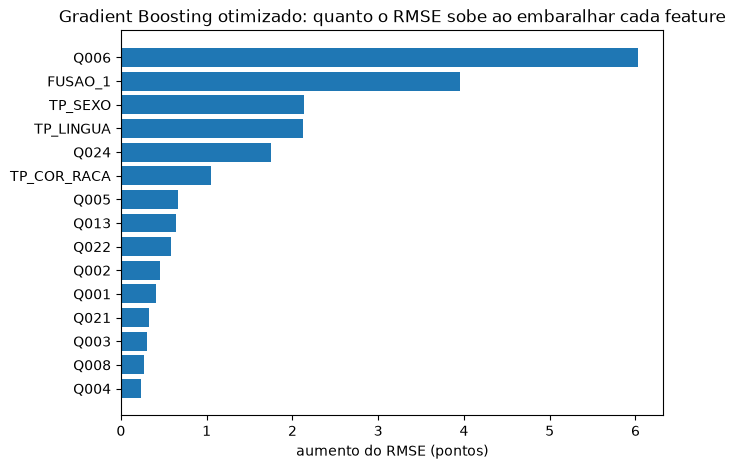

In [24]:
if "Gradient Boosting" in melhores:
    imp = importancia_por_permutacao(melhores["Gradient Boosting"])
    print(imp.tail(6).round(2).to_string())
    grafico_importancia(imp, "Gradient Boosting otimizado: quanto o RMSE sobe ao embaralhar cada feature", "aumento do RMSE (pontos)")

### Passo 3: nota real × nota prevista e salvar

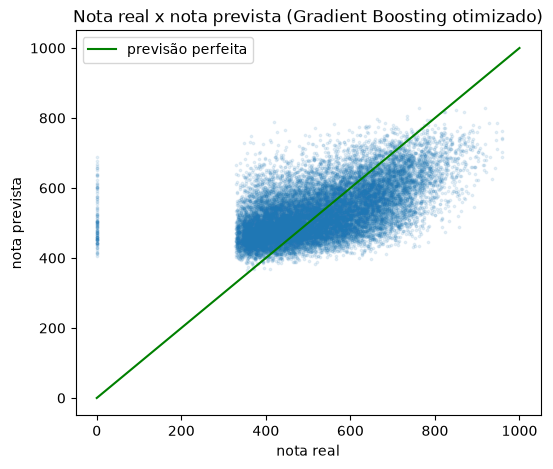

In [25]:
if "Gradient Boosting" in melhores:
    real_x_previsto(melhores["Gradient Boosting"], "Gradient Boosting otimizado")
    joblib.dump(melhores["Gradient Boosting"], f"../models/gradient_boosting_otimizado_{NOME}.joblib")

## 9. Stacking

**O que é:** `StackingRegressor`: junta as previsões de vários modelos (por exemplo Ridge, Random Forest e Gradient Boosting) e um modelo final aprende a combiná-las.

**Pontos de atenção:** Só faz sentido depois dos outros modelos treinados e comparados. Treina os modelos base várias vezes (validação cruzada interna), então é o mais caro. Escolhas: quais modelos entram, o modelo final (por exemplo `Ridge`) e o `cv` interno.

### Sem busca

O stacking já leva cerca de **15 a 20 minutos** só para medir uma configuração (cada modelo de base é treinado várias vezes), então 10 configurações seriam mais de **2 horas**. Ele **fica com a configuração inicial** do notebook 02. Uma saída barata é montar o stacking **com os modelos já otimizados** das seções 2 a 8 como modelos de base, sem nova busca no empilhamento.

## 10. KNN (vizinhos mais próximos)

**O que é:** `KNeighborsRegressor`: para cada participante, acha os k mais parecidos no treino e prevê a média da nota deles.

**Pontos de atenção:** Precisa de `StandardScaler` dentro do Pipeline (usa distância). Com mais de 2 milhões de linhas a previsão é lenta, então é preciso planejar tempo e memória e registrar os limites. Hiperparâmetros: `n_neighbors`, `weights`, `p`.

### Sem busca

No notebook 02 medimos cerca de **6 minutos por dobra** para o KNN, ou **~20 minutos por configuração**. Uma busca com 10 configurações levaria **mais de 3 horas** (e mais se `n_neighbors` for grande), então o KNN **fica com a configuração inicial** do notebook 02. Se for um dos 3 melhores na seção 11 do 02, vale planejar a busca à parte, com `n_neighbors` entre 10 e 200 e `weights` uniforme ou por distância.

## 11. Comparação dos modelos

Uma tabela com RMSE, MAE, R² (média ± desvio), tempo e dataset de cada modelo, para escolher os três melhores regressores distintos.

### Passo 1: antes × depois da busca

O PDF pede comparar **antes e depois** da busca. O "antes" é o RMSE da configuração inicial, medido no notebook 02. Para trazê-lo para cá, rode **uma vez** no notebook 02, depois da seção 11, esta célula:

```python
comparacao.to_csv("../resultados/tabelas/comparacao_modelos_config_inicial.csv")
```

Se o arquivo não existir, a tabela mostra só o "depois".

In [26]:
arquivo = Path("../resultados/tabelas/comparacao_modelos_config_inicial.csv")
inicial = pd.read_csv(arquivo, index_col=0) if arquivo.exists() else None
if inicial is None:
    print("Arquivo da configuração inicial não encontrado: mostrando só o resultado depois da busca.")

linhas = []
for nome, r in resultados.items():
    linha = {"modelo": nome, "RMSE_otimizado": r.loc["RMSE", "média"], "RMSE_desvio": r.loc["RMSE", "desvio"],
             "R2": r.loc["R2", "média"], "tempo_s": r.loc["tempo_s", "média"]}
    if inicial is not None and nome in inicial.index:
        linha["RMSE_inicial"] = inicial.loc[nome, "RMSE"]
        linha["ganho"] = inicial.loc[nome, "RMSE"] - r.loc["RMSE", "média"]
    linha["melhores_parametros"] = str(parametros[nome])
    linhas.append(linha)
comparacao_otimizada = pd.DataFrame(linhas).set_index("modelo").sort_values("RMSE_otimizado")
comparacao_otimizada.round(3)

Arquivo da configuração inicial não encontrado: mostrando só o resultado depois da busca.


,RMSE_otimizado,RMSE_desvio,R2,tempo_s,melhores_parametros
modelo,,,,,
Gradient Boosting,107.680,0.178,0.331,223.988,{'l2_regularization': np.float64(0.24400607090...
Bagging,109.083,0.154,0.313,23.760,"{'estimator__max_depth': 15, 'estimator__min_s..."
Random Forest,109.138,0.159,0.313,19.205,"{'max_depth': 15, 'max_features': 0.3, 'min_sa..."
Pasting,109.146,0.158,0.312,18.098,"{'estimator__max_depth': 15, 'estimator__min_s..."
Árvore de decisão,110.337,0.148,0.297,8.310,"{'max_depth': 25, 'max_features': 0.8, 'min_sa..."
Ridge,111.153,0.145,0.287,0.952,{'ridge__alpha': np.float64(461.93473743773814)}
SVR linear,111.153,0.145,0.287,5.846,{'linearsvr__C': np.float64(0.0293802793870353...


### Passo 2: gráfico

O RMSE de cada modelo com o desvio entre as dobras. Se houver o "antes", ele aparece ao lado. Ganhos menores que o desvio não provam melhora.

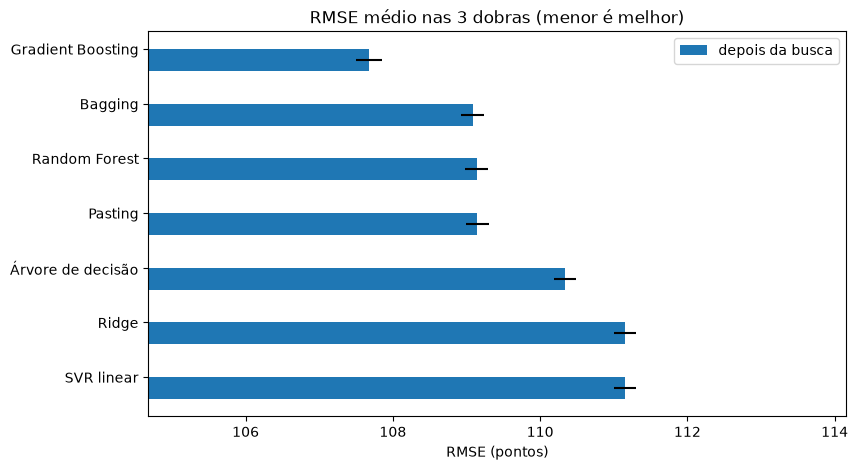

In [27]:
ordem = comparacao_otimizada.sort_values("RMSE_otimizado", ascending=False)
plt.figure(figsize=(9, 5))
posicao = np.arange(len(ordem))
if "RMSE_inicial" in ordem:
    plt.barh(posicao + 0.2, ordem["RMSE_inicial"], height=0.4, color="lightgray", label="configuração inicial")
plt.barh(posicao - 0.2, ordem["RMSE_otimizado"], height=0.4, xerr=ordem["RMSE_desvio"], color="tab:blue", label="depois da busca")
plt.yticks(posicao, ordem.index)
plt.xlim(ordem["RMSE_otimizado"].min() - 3, ordem["RMSE_otimizado"].max() + 3)
plt.title("RMSE médio nas 3 dobras (menor é melhor)")
plt.xlabel("RMSE (pontos)")
plt.legend()
plt.show()

### Passo 3: os 3 melhores regressores distintos

Para o PDF, são os 3 melhores **regressores distintos** (sem o baseline), pelo RMSE médio. Bagging e pasting são variações do mesmo método e contam como um.

In [28]:
familia = {"Ridge": "Linear", "Árvore de decisão": "Árvore", "SVR linear": "SVR", "Bagging": "Bagging/Pasting",
           "Pasting": "Bagging/Pasting", "Random Forest": "Random Forest", "Gradient Boosting": "Gradient Boosting"}
top3 = comparacao_otimizada.assign(familia=comparacao_otimizada.index.map(familia)).drop_duplicates("familia").head(3)
print("Os 3 melhores regressores distintos entre os que passaram pela busca:")
top3[["familia", "RMSE_otimizado", "RMSE_desvio", "tempo_s"]].round(3)

Os 3 melhores regressores distintos entre os que passaram pela busca:


,familia,RMSE_otimizado,RMSE_desvio,tempo_s
modelo,,,,
Gradient Boosting,Gradient Boosting,107.680,0.178,223.988
Bagging,Bagging/Pasting,109.083,0.154,23.760
Random Forest,Random Forest,109.138,0.159,19.205


## 12. Comparação dos datasets com o modelo otimizado

Um modelo por dataset: o **melhor modelo otimizado que não seja muito lento** (menos de 120 s por dobra), com os hiperparâmetros que a busca achou, treinado nos 8 datasets nas mesmas dobras, mais a regressão linear como referência. O melhor modelo é salvo em `models/` para cada dataset. Só as colunas mudam: as linhas e as dobras são as mesmas.

In [29]:
from sklearn.linear_model import LinearRegression

regressao_linear = make_pipeline(StandardScaler(), LinearRegression())
rapidos = comparacao_otimizada[comparacao_otimizada["tempo_s"] < 120]
melhor = rapidos.index[0]
print(f"Melhor modelo otimizado rápido: {melhor} (RMSE {rapidos.loc[melhor, 'RMSE_otimizado']:.3f}, {rapidos.loc[melhor, 'tempo_s']:.0f} s por dobra)")
print("Hiperparâmetros:", parametros[melhor])

modelos = {"Regressão linear": regressao_linear, f"{melhor} (otimizado)": melhores[melhor]}
por_dataset = []
for nome in DATASETS:
    X, y = carregar(nome)                      # a função avaliar usa o X e o y atuais
    for modelo_nome, modelo in modelos.items():
        r = avaliar(modelo)
        por_dataset.append({"dataset": nome, "features": X.shape[1], "modelo": modelo_nome,
                            "RMSE": r.loc["RMSE", "média"], "RMSE_desvio": r.loc["RMSE", "desvio"],
                            "MAE": r.loc["MAE", "média"], "R2": r.loc["R2", "média"], "tempo_s": r.loc["tempo_s", "média"]})
    joblib.dump(clone(melhores[melhor]).fit(X, y), f"../models/{melhor.lower().replace(' ', '_')}_otimizado_{nome}.joblib")
    print(f"{nome:<32} ok")
X, y = carregar(NOME)                          # volta ao dataset de trabalho

tabela_datasets = pd.DataFrame(por_dataset)
tabela_datasets.round(3)

Melhor modelo otimizado rápido: Bagging (RMSE 109.083, 24 s por dobra)
Hiperparâmetros: {'estimator__max_depth': 15, 'estimator__min_samples_leaf': 34, 'max_features': 0.8, 'max_samples': 0.7, 'n_estimators': 24}
dataset_1_fundido                ok
dataset_1_features               ok
dataset_2_escola                 ok
dataset_2_features_escola        ok
dataset_3_sem_escola             ok
dataset_3_sem_escola_features    ok
dataset_3_escola                 ok
dataset_3_escola_features        ok


,dataset,features,modelo,RMSE,RMSE_desvio,MAE,R2,tempo_s
0,dataset_1_fundido,30,Regressão linear,111.153,0.178,86.960,0.287,1.229
1,dataset_1_fundido,30,Bagging (otimizado),109.083,0.189,85.273,0.313,22.800
2,dataset_1_features,33,Regressão linear,111.146,0.178,86.951,0.287,1.276
3,dataset_1_features,33,Bagging (otimizado),109.170,0.185,85.296,0.312,26.342
4,dataset_2_escola,34,Regressão linear,110.747,0.183,86.596,0.292,1.368
5,dataset_2_escola,34,Bagging (otimizado),108.720,0.184,84.923,0.318,25.500
6,dataset_2_features_escola,37,Regressão linear,110.742,0.183,86.590,0.292,1.376
7,dataset_2_features_escola,37,Bagging (otimizado),108.684,0.179,84.917,0.318,28.858
8,dataset_3_sem_escola,38,Regressão linear,110.752,0.185,86.570,0.292,1.323
9,dataset_3_sem_escola,38,Bagging (otimizado),109.089,0.184,85.318,0.313,23.548


modelo                         Bagging (otimizado)  Regressão linear
dataset                                                             
dataset_1_fundido                          109.083           111.153
dataset_1_features                         109.170           111.146
dataset_2_escola                           108.720           110.747
dataset_2_features_escola                  108.684           110.742
dataset_3_sem_escola                       109.089           110.752
dataset_3_sem_escola_features              109.081           110.744
dataset_3_escola                           108.597           110.384
dataset_3_escola_features                  108.615           110.378


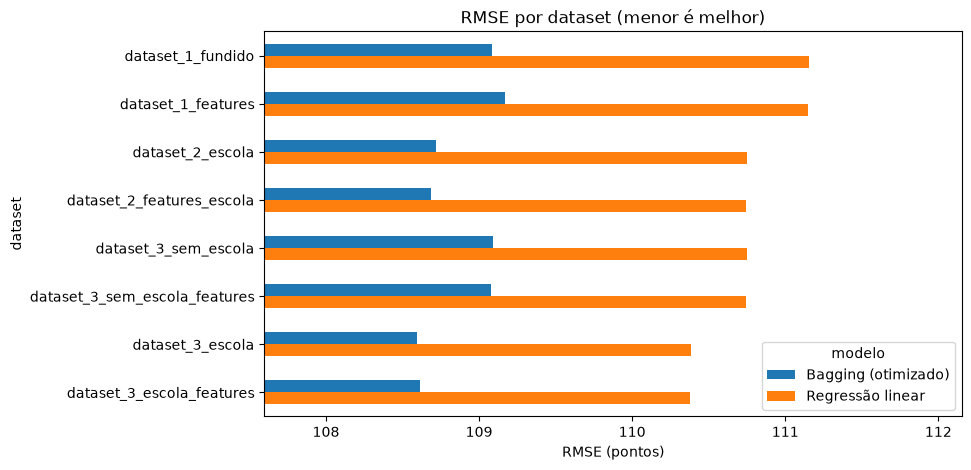

In [30]:
pivo = tabela_datasets.pivot(index="dataset", columns="modelo", values="RMSE").loc[DATASETS]
print(pivo.round(3).to_string())

pivo.plot.barh(figsize=(9, 5), title="RMSE por dataset (menor é melhor)")
plt.xlim(pivo.min().min() - 1, pivo.max().max() + 1)
plt.xlabel("RMSE (pontos)")
plt.gca().invert_yaxis()
plt.show()